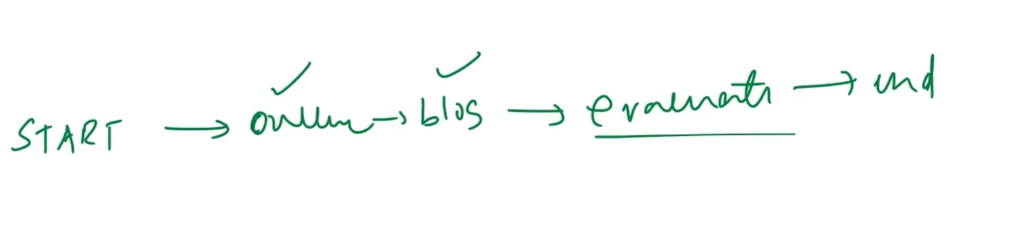

In [11]:
from typing import TypedDict

from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langgraph.graph import END, START, StateGraph


In [12]:
load_dotenv()

True

In [13]:
llm = ChatGroq(model="openai/gpt-oss-120b" )

In [14]:
class BlogState(TypedDict):
    title : str
    outline : str
    blog : str
    rating : str

In [15]:
def llm_outline(state : BlogState) -> BlogState:

    topic = state['title']

    prompt = f"Generate a detailed outline on a given topic {topic}"

    content = llm.invoke(prompt).content

    state['outline'] = content

    return state


In [16]:
def llm_blog(state : BlogState) -> BlogState:

    topic = state['title']
    blog_outline = state['outline']

    prompt = f"write a detailed blog on given topic  {topic} \n using these outlines {blog_outline}"

    content = llm.invoke(prompt).content

    state['blog'] = content

    return state

In [17]:
def llm_rating_blog(state : BlogState) -> BlogState:
    
    topic = state['title']
    blog = state['blog']

    prompt = f"rate my blog in scale 0-5 on topic  {topic} \n using this blog {blog}"

    content = llm.invoke(prompt).content

    state['rating'] = content

    return state

In [18]:
graph = StateGraph(BlogState)

# making nodes 
graph.add_node('create_outline' , llm_outline)
graph.add_node('blog' , llm_blog)
graph.add_node('rating' , llm_rating_blog)

# making edges 

graph.add_edge(START , 'create_outline')
graph.add_edge('create_outline' , 'blog')
graph.add_edge('blog' , 'rating')
graph.add_edge('rating' , END)

# compile a graph

workflow = graph.compile()

In [19]:
intial_state = {"title" : "Impact of AI"}

final_state = workflow.invoke(intial_state)

print(final_state)

{'title': 'Impact of AI', 'outline': '**Title: The Impact of Artificial Intelligence (AI) – A Comprehensive Outline**\n\n---\n\n### I. Introduction  \n   A. Definition of Artificial Intelligence  \n   B. Brief history and evolution of AI technologies  \n   C. Scope of the outline – why studying AI’s impact matters today  \n\n### II. Economic Impact  \n   A. Productivity and Growth  \n      1. Automation of routine tasks  \n      2. Augmented decision‑making & predictive analytics  \n      3. Case studies: Manufacturing (smart factories), Finance (algorithmic trading)  \n   B. Labor Market Transformation  \n      1. Job displacement vs. job creation (e.g., data scientists, AI ethicists)  \n      2. Skills gap and the need for reskilling/upskilling programs  \n      3. Regional disparities (advanced economies vs. developing nations)  \n   C. New Business Models & Industries  \n      1. AI‑as‑a‑Service (AIaaS) platforms  \n      2. AI‑driven products (autonomous vehicles, smart assistants

In [20]:
print(final_state['outline'])

**Title: The Impact of Artificial Intelligence (AI) – A Comprehensive Outline**

---

### I. Introduction  
   A. Definition of Artificial Intelligence  
   B. Brief history and evolution of AI technologies  
   C. Scope of the outline – why studying AI’s impact matters today  

### II. Economic Impact  
   A. Productivity and Growth  
      1. Automation of routine tasks  
      2. Augmented decision‑making & predictive analytics  
      3. Case studies: Manufacturing (smart factories), Finance (algorithmic trading)  
   B. Labor Market Transformation  
      1. Job displacement vs. job creation (e.g., data scientists, AI ethicists)  
      2. Skills gap and the need for reskilling/upskilling programs  
      3. Regional disparities (advanced economies vs. developing nations)  
   C. New Business Models & Industries  
      1. AI‑as‑a‑Service (AIaaS) platforms  
      2. AI‑driven products (autonomous vehicles, smart assistants)  
      3. Marketplace effects – platform economies, gig

In [21]:
print(final_state['rating'])

**Rating: 4.3 / 5**

---

## Why it scores that high  

| Criterion | Score (0‑5) | Comments |
|-----------|------------|----------|
| **Clarity & Structure** | 5 | The outline (Intro → Economic → Social → Ethical → Technological → Environmental → Geopolitical → Future) is logical and easy to follow. Headings, tables, and bullet points break up dense material nicely. |
| **Depth & Breadth of Content** | 4.5 | Covers the major dimensions of AI impact (economy, society, ethics, tech, environment, geopolitics) with concrete examples, stats, and case studies. The “future outlook” section could be expanded a bit more, but overall it’s comprehensive. |
| **Evidence & Sources** | 4 | Uses reputable data points (World Economic Forum, McKinsey, EU AI Act, etc.) and cites specific numbers (e.g., $13 trillion GDP boost, 500 t CO₂ for GPT‑3). A few inline citations or footnotes would boost credibility further. |
| **Originality & Insight** | 4 | The synthesis of “AI‑as‑a‑Service,” “prompt engineer